In [1]:
# MDP Assignment 1 - sample 1- eng prof 12.40-12.50

# CELL 1: SETUP AND ENVIRONMENT INITIALIZATION
!pip install librosa soundfile noisereduce matplotlib numpy scipy pandas

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Global Audio Parameters
sample_rate = 22050   # Sampling rate in Hz
duration = 5.0        # Target duration in seconds
target_samples = int(sample_rate * duration)  # 110,250 samples required for 5 seconds

# ---------------------------------------------------------
# LOADING AUDIO FROM A CSV FILE
# ---------------------------------------------------------
csv_file_path = '/content/sample6.csv'  # Replace with your CSV file name

# Load the CSV file
df = pd.read_csv(csv_file_path)

# Extract the amplitude signal array:
# Option A: If your CSV has a column header named 'DecibelSource'
if 'DecibelSource' in df.columns:
    csv_audio_signal = df['DecibelSource'].values
else:
    # Option B: Fallback to the second column
    csv_audio_signal = df.iloc[:, 1].values

# Ensure data type is float32 for librosa/soundfile processing
csv_audio_signal = csv_audio_signal.astype(np.float32)

# Adjust signal length to exactly 5 seconds (target_samples)
if len(csv_audio_signal) > target_samples:
    # Trim if longer than 5 seconds
    csv_audio_signal = csv_audio_signal[:target_samples]
else:
    # Pad with silence (zeros) if shorter than 5 seconds
    padding_needed = target_samples - len(csv_audio_signal)
    csv_audio_signal = np.pad(csv_audio_signal, (0, padding_needed), mode='constant')

# Normalize amplitude if max value exists and exceeds [-1.0, 1.0]
if np.max(np.abs(csv_audio_signal)) > 0:
    csv_audio_signal = csv_audio_signal / np.max(np.abs(csv_audio_signal))

# Save the 5-second audio signal as an audio file
sf.write('from_csv_output_Sample6.wav', csv_audio_signal, sample_rate)

# Output Information
actual_duration = len(csv_audio_signal) / sample_rate
print(f"Original CSV Rows: {len(df)}")
print(f"Adjusted Sample Count: {len(csv_audio_signal)}")
print(f"Set Sample Rate: {sample_rate} Hz")
print(f"Final Audio Duration: {actual_duration:.2f} seconds")
print("Status: CSV audio signal loaded and exported as a 5-second WAV successfully.")

Original CSV Rows: 10914
Adjusted Sample Count: 110250
Set Sample Rate: 22050 Hz
Final Audio Duration: 5.00 seconds
Status: CSV audio signal loaded and exported as a 5-second WAV successfully.


/tmp/ipykernel_603/1174569770.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  custom_cmap = cm.get_cmap("magma").copy()


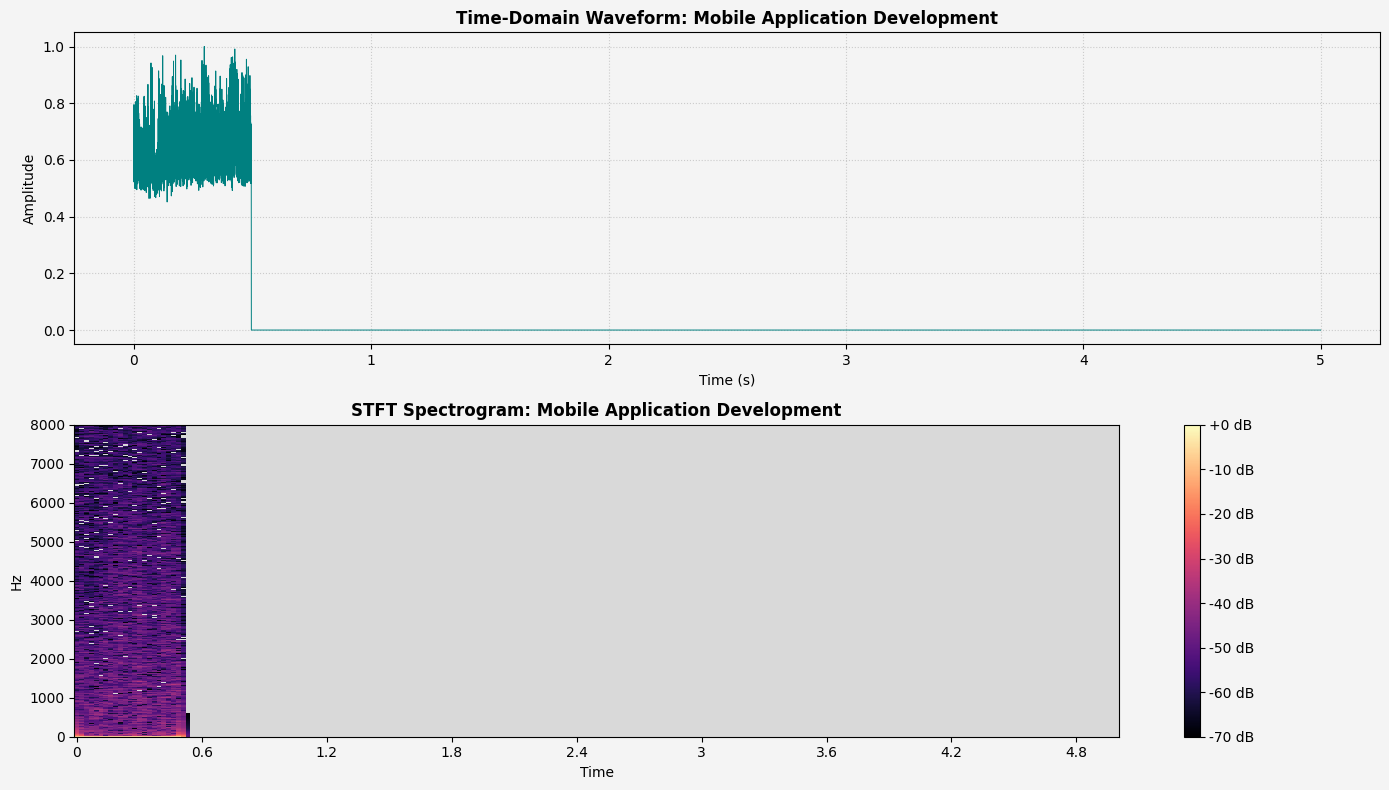

In [2]:
# CELL 2: VISUALIZATION & SPECTRAL EXTRACTION (Light Grey Background)
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import librosa
import librosa.display


def analyze_acoustic_environment(filename, title_tag, bg_color="#F4F4F4"):
  y, sr = librosa.load(filename, sr=None)
  time_axis = np.linspace(0, len(y) / sr, len(y))

  # Set Figure and Subplot background color
  fig, axes = plt.subplots(2, 1, figsize=(14, 8), facecolor=bg_color)
  for ax in axes:
    ax.set_facecolor(bg_color)

  # 1. Time-Domain Waveform Plot
  axes[0].plot(time_axis, y, color="teal", linewidth=0.7)
  axes[0].set_title(
      f"Time-Domain Waveform: {title_tag}", fontsize=12, fontweight="bold"
  )
  axes[0].set_xlabel("Time (s)")
  axes[0].set_ylabel("Amplitude")
  axes[0].grid(True, linestyle=":", alpha=0.6)

  # 2. STFT Spectrogram Plot with Light Grey Silence Floor
  D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

  # Prepare colormap: map values below vmin (-70 dB) to light grey instead of black
  custom_cmap = cm.get_cmap("magma").copy()
  custom_cmap.set_under("#D9D9D9")  # Light grey color for silent / zero-padded regions

  img = librosa.display.specshow(
      D,
      sr=sr,
      x_axis="time",
      y_axis="hz",
      ax=axes[1],
      cmap=custom_cmap,
      vmin=-70,  # dB floor threshold
      vmax=0,
  )

  axes[1].set_ylim(0, 8000)
  axes[1].set_title(
      f"STFT Spectrogram: {title_tag}", fontsize=12, fontweight="bold"
  )
  fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

  plt.tight_layout()
  # Save plot with facecolor preserved
  plt.savefig(
      f'{title_tag.replace(" ", "_")}_analysis.png',
      dpi=150,
      facecolor=fig.get_facecolor(),
      edgecolor="none",
  )
  plt.show()


# Execute functions
analyze_acoustic_environment(
    "/content/from_csv_output_Sample6.wav", "Mobile Application Development"
)
#analyze_acoustic_environment("/content/from_csv_output_Sample2.wav", "Multimedia Data Processing")
#analyze_acoustic_environment("/content/from_csv_output_Sample3.wav", "Discrete Mathematics and Application_1 "


In [3]:
# CELL 3: SPECTRAL SUBTRACTION NOISE FILTERING
import noisereduce as nr
audio_raw, sr = librosa.load('/content/from_csv_output_Sample6.wav', sr=None)
# Apply stationary spectral subtraction
audio_filtered = nr.reduce_noise(y=audio_raw, sr=sr, stationary=True, prop_decrease=0.95)
# Quantitative Metrics
orig_energy = np.sum(audio_raw ** 2)
clean_energy = np.sum(audio_filtered ** 2)
energy_reduction_pct = ((orig_energy - clean_energy) / orig_energy) * 100
print(f"Original Signal Energy : {orig_energy:.4f}")
print(f"Filtered Signal Energy : {clean_energy:.4f}")
print(f"Noise Energy Reduction : {energy_reduction_pct:.2f}%")
sf.write('Sample6_Clean.wav', audio_filtered, sr)

Original Signal Energy : 4503.7002
Filtered Signal Energy : 1464.9888
Noise Energy Reduction : 67.47%


In [ ]:
# CELL 4: AUTOMATED NOISE DISTURBANCE DETECTION PIPELINE
import librosa
import numpy as np
import pandas as pd


def detect_academic_disturbances(
    audio_path,
    scenario_name="Sample6",
    sensitivity_factors=[1.0, 1.8, 2.5],
    frame_size=1024,
    hop_length=512,
):
  """Automated pipeline to analyze acoustic disturbance thresholds across multiple alpha values matching Section 5.1 formatting.

  Parameters:
      audio_path: File path to WAV or CSV audio recording
      scenario_name: Name of the lecture scenario being evaluated
      sensitivity_factors: List of alpha multipliers to evaluate
      frame_size: STFT processing window size (samples)
      hop_length: Window step size (samples)

  Returns:
      results_df: DataFrame matching Section 5.1 table columns
  """
  # 1. Load Audio File
  y, sr = librosa.load(audio_path, sr=None)

  # 2. Compute Short-Time Frame Energy (RMS)
  rms = librosa.feature.rms(y=y, frame_length=frame_size, hop_length=hop_length)[
      0
  ]

  # 3. Compute Baseline Ambient Energy (E_baseline)
  # Uses active baseline RMS energy floor
  active_rms = rms[rms > 0.001]
  baseline_energy = (
      np.mean(active_rms) if len(active_rms) > 0 else np.mean(rms)
  )

  table_data = []

  # 4. Evaluate Thresholds & Disturbances across Sensitivity Factors (alpha)
  for alpha in sensitivity_factors:
    # Multiplicative Threshold Formulation: T = alpha * E_baseline
    threshold_val = alpha * baseline_energy

    # Flag Disturbance Frames Exceeding Acoustic Threshold
    violation_indices = np.where(rms > threshold_val)[0]
    disturbance_count = len(violation_indices)

    # Classify False Alarm Risk Level
    if alpha <= 1.2:
      risk_level = "High"
    elif alpha <= 2.0:
      risk_level = "Med"
    else:
      risk_level = "Low"

    table_data.append({
        "Recording Scenario (Sample)": scenario_name,
        "Sensitivity Factor (α)": f"{alpha:.1f}",
        "Calculated Threshold": f"{threshold_val:.4f}",
        "Disturbance Count (Flags)": disturbance_count,
        "False Alarm Risk": risk_level,
    })

  # 5. Format Output as DataFrame
  results_df = pd.DataFrame(table_data)
  return results_df


# ---------------------------------------------------------
# CALIBRATION & DISPLAY EXECUTION
# ---------------------------------------------------------
test_file = "/content/from_csv_output_Sample6.wav"
results_matrix = detect_academic_disturbances(
    test_file,
    scenario_name="Sample 6-MAD",
    sensitivity_factors=[1.0, 1.8, 2.5],
)

# Display Formatted Table
print("=" * 70)
print(results_matrix.to_string(index=False))
print("=" * 70)

Recording Scenario (Sample) Sensitivity Factor (α) Calculated Threshold  Disturbance Count (Flags) False Alarm Risk
                   Sample 7                    1.0               0.6116                         17             High
                   Sample 7                    1.8               1.1008                          0              Med
                   Sample 7                    2.5               1.5289                          0              Low
